# Comparação dos algoritmos

Este notebook reúne os resultados dos quatro notebooks de modelagem (`modelagem-mlp`, `modelagem-nb`, `modelagem-xgb` e `modelagem-rl`) e compara os algoritmos entre si. Ele **não treina modelos**: só lê o que cada notebook gravou em `data/results/modelagem/`. Por isso, deve ser executado **depois** dos quatro.

## Estratégia de avaliação

- **Divisão treino/teste**: validação cruzada estratificada com 10 folds (`StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`). Cada cliente aparece no teste exatamente uma vez. Cada fold de teste tem 285 clientes e 44 ou 45 churns (15,4% a 15,8%), a mesma proporção da base (15,6%).
- **Mesmos folds para todos**: as partições foram geradas uma única vez e gravadas em `data/processed/folds.csv`. Todos os algoritmos, todas as configurações e as duas bases (com e sem `inativo`) usam exatamente os mesmos pares treino/teste. Por isso as comparações podem ser **pareadas fold a fold**: a diferença entre dois modelos em cada fold elimina a variação causada pela dificuldade de cada partição.
- **Sem vazamento**: transformações linha a linha (remoção de duplicatas, recodificação, one-hot, `log1p`, idade numérica) são feitas na base inteira, porque não aprendem nada com os dados. As que aprendem parâmetros (padronização da MLP e da regressão logística, pesos de classe e priors) são ajustadas **só no treino de cada fold**.
- **Duas bases**: todos os modelos são avaliados com e sem o atributo `inativo` (`Status`), por suspeita de vazamento. A base **sem `inativo`** é a referência para as escolhas.
- **Ponto de operação**: o cliente é classificado como churn quando a probabilidade prevista é ≥ 0,5. O desbalanceamento é tratado em todos os algoritmos pelo critério "balanced" (pesos de classe, `scale_pos_weight` ou priors uniformes).
- **Escolha das configurações**: em cada notebook, a configuração que representa o algoritmo é a de maior PR-AUC média na base sem `inativo`, com uma regra de parcimônia: entre as que ficam a menos de um desvio da melhor, fica a mais simples.
- **Limitação**: a escolha da configuração e a avaliação usam os **mesmos folds** (não há validação cruzada aninhada). Os números das configurações escolhidas são, por isso, levemente otimistas, mais nos algoritmos com grades maiores (XGBoost, com 12 configurações; regressão logística, com 6).

## Medidas de avaliação e fórmulas

A **matriz de confusão** resume os acertos e erros com a classe churn como positiva:

| | previsto não churn | previsto churn |
|---|---|---|
| **real não churn** | VN (verdadeiro negativo) | FP (falso positivo, falso alarme) |
| **real churn** | FN (falso negativo, churn perdido) | VP (verdadeiro positivo) |

| medida | fórmula | o que mede |
|---|---|---|
| **Recall** (sensibilidade, classe churn) | $\dfrac{VP}{VP + FN}$ | fração dos churns que o modelo encontra. **Métrica principal**: cada FN é um cliente perdido sem ação de retenção |
| **Especificidade** | $\dfrac{VN}{VN + FP}$ | fração dos clientes que ficam e são reconhecidos como tal |
| Precisão (só como parte do F1) | $\dfrac{VP}{VP + FP}$ | fração dos alarmes de churn que estão corretos |
| **F1 macro** | $\dfrac{1}{2}\left(F1_{\text{churn}} + F1_{\text{não churn}}\right)$, com $F1_c = \dfrac{2\,P_c R_c}{P_c + R_c}$ | resumo do desempenho geral, com peso igual para as duas classes, para que a classe churn não seja abafada pela majoritária |
| **Entropia cruzada (log loss)** | $-\dfrac{1}{n}\sum_{i=1}^{n}\left[y_i \log p_i + (1 - y_i)\log(1 - p_i)\right]$ | qualidade das probabilidades; pune fortemente os erros cometidos com alta confiança (quanto menor, melhor) |
| **PR-AUC** (*average precision*) | $\sum_k (R_k - R_{k-1})\, P_k$, percorrendo os limiares em ordem decrescente de probabilidade | área sob a curva precisão-recall: capacidade de pôr os churns no topo da lista, independentemente do limiar. A linha de base (modelo aleatório) é a taxa de churn, **0,156** |

Medidas descartadas, por causa do desbalanceamento (84% de não churn):
- **acurácia**: um modelo que sempre responde "não churn" teria ~84% sem acertar nenhum churn;
- **F1 ponderado**: dá mais peso à classe majoritária;
- **acurácia balanceada**: é a média de recall e especificidade, já analisados separadamente;
- **ROC-AUC**: com muito mais não churn do que churn, a taxa de falsos positivos fica baixa mesmo com muitos falsos alarmes, o que deixa a curva otimista. A PR-AUC foca na classe positiva.

Todas as medidas são calculadas em cada fold de teste e resumidas em **média ± desvio** nos 10 folds. As matrizes de confusão são **somadas** nos 10 folds (cada cliente aparece uma vez).

## Carregamento dos resultados

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import precision_recall_curve

from comum import (ALGORITMOS, METRICAS, N_CHURN, N_LINHAS, RESULTS_DIR, carregar_base,
                   diferenca_pareada, formatar_metricas, ler_escolhida, ler_resultados,
                   resultado_salvo, salvar_tabela, tabela_desbalanceamento)

NOMES = {'mlp': 'MLP', 'nb': 'Naive Bayes', 'xgb': 'XGBoost', 'rl': 'Regressão logística'}
BASES = ['sem-status', 'com-status']
TAXA_CHURN = N_CHURN / N_LINHAS

metricas, matrizes, probas = ler_resultados()
assert (matrizes[['tn', 'fp', 'fn', 'tp']].sum(axis=1) == N_LINHAS).all()
assert (matrizes[['fn', 'tp']].sum(axis=1) == N_CHURN).all()

ESCOLHIDAS = {alg: ler_escolhida(alg) for alg in ALGORITMOS}
for alg, config in ESCOLHIDAS.items():
    for base in BASES:
        assert (alg, config, base) in probas, f'falta {alg} {config} {base}: rode o notebook de modelagem'
print('configurações escolhidas:')
for alg, config in ESCOLHIDAS.items():
    print(f'  {NOMES[alg]:<20} {config}')

# resultados das escolhidas no formato do avaliar: (alg, base) -> {'por_fold', 'matriz'}
res = {(alg, base): resultado_salvo(metricas, matrizes, alg, ESCOLHIDAS[alg], base)
       for alg in ALGORITMOS for base in BASES}

_, y = carregar_base(com_status=True)

configurações escolhidas:
  MLP                  relu_adam_32-32-32
  Naive Bayes          sem-redundantes
  XGBoost              d2_lr0.3
  Regressão logística  C0.1


## Tabela comparativa

Configuração escolhida de cada algoritmo, nas duas bases: média ± desvio nos 10 folds, e os erros (FN e FP) somados nos folds. As linhas de referência são as regras de um atributo da análise exploratória e o classificador trivial que responde sempre "não churn".

In [2]:
linhas = []
for base in BASES:
    for alg in ALGORITMOS:
        r = res[(alg, base)]
        (tn, fp), (fn, tp) = r['matriz']
        linhas.append({'base': base, 'algoritmo': NOMES[alg], 'config': ESCOLHIDAS[alg],
                       **formatar_metricas(r['por_fold']), 'FN': fn, 'FP': fp})

referencias = [
    {'base': '—', 'algoritmo': 'regra: reclamou → churn', 'config': '—', 'recall': '0.426', 'especificidade': '0.983'},
    {'base': '—', 'algoritmo': 'regra: inativo → churn', 'config': '—', 'recall': '0.729', 'especificidade': '0.851'},
    {'base': '—', 'algoritmo': 'trivial: sempre não churn', 'config': '—', 'recall': '0.000',
     'especificidade': '1.000', 'pr_auc': f'{TAXA_CHURN:.3f}', 'FN': N_CHURN, 'FP': 0},
]
tabela = pd.DataFrame(linhas + referencias)
tabela.to_csv(RESULTS_DIR / 'comparacao-tabela.csv', index=False)
salvar_tabela(tabela, 'comparacao-tab-geral')
tabela

,base,algoritmo,config,recall,especificidade,f1_macro,log_loss,pr_auc,FN,FP
0,sem-status,MLP,relu_adam_32-32-32,0.914 ± 0.054,0.956 ± 0.009,0.910 ± 0.020,0.159 ± 0.054,0.932 ± 0.035,38.0,105.0
1,sem-status,Naive Bayes,sem-redundantes,0.791 ± 0.069,0.802 ± 0.016,0.712 ± 0.027,0.959 ± 0.248,0.710 ± 0.096,93.0,476.0
2,sem-status,XGBoost,d2_lr0.3,0.914 ± 0.059,0.958 ± 0.012,0.913 ± 0.026,0.129 ± 0.037,0.932 ± 0.037,38.0,100.0
3,sem-status,Regressão logística,C0.1,0.840 ± 0.082,0.855 ± 0.023,0.774 ± 0.033,0.351 ± 0.032,0.748 ± 0.082,71.0,348.0
4,com-status,MLP,relu_adam_32-32-32,0.903 ± 0.060,0.963 ± 0.009,0.915 ± 0.025,0.174 ± 0.085,0.936 ± 0.037,43.0,89.0
5,com-status,Naive Bayes,sem-redundantes,0.892 ± 0.047,0.805 ± 0.026,0.745 ± 0.023,1.088 ± 0.264,0.728 ± 0.095,48.0,468.0
6,com-status,XGBoost,d2_lr0.3,0.923 ± 0.046,0.963 ± 0.015,0.922 ± 0.031,0.119 ± 0.041,0.940 ± 0.038,34.0,89.0
7,com-status,Regressão logística,C0.1,0.865 ± 0.063,0.859 ± 0.025,0.786 ± 0.027,0.340 ± 0.032,0.747 ± 0.069,60.0,339.0
8,—,regra: reclamou → churn,—,0.426,0.983,NaN,NaN,NaN,NaN,NaN
9,—,regra: inativo → churn,—,0.729,0.851,NaN,NaN,NaN,NaN,NaN


### Todas as configurações salvas

Inclui as configurações finais de cada notebook e as versões sem o tratamento do desbalanceamento (`_sem-pesos` e `priors-base`). Serve de apoio à discussão sobre o efeito das parametrizações; as grades completas estão em cada notebook de modelagem.

In [3]:
completa = []
for (alg, config, base), _ in sorted(probas.items()):
    r = resultado_salvo(metricas, matrizes, alg, config, base)
    (tn, fp), (fn, tp) = r['matriz']
    completa.append({'algoritmo': NOMES[alg], 'config': config, 'base': base,
                     'escolhida': '✔' if config == ESCOLHIDAS[alg] else '',
                     **formatar_metricas(r['por_fold']), 'FN': fn, 'FP': fp})
tab = pd.DataFrame(completa)
salvar_tabela(tab, 'comparacao-tab-todas-configs')
tab

,algoritmo,config,base,escolhida,recall,especificidade,f1_macro,log_loss,pr_auc,FN,FP
0,MLP,relu_adam_32,com-status,,0.944 ± 0.053,0.907 ± 0.017,0.859 ± 0.021,0.191 ± 0.026,0.901 ± 0.048,25,224
1,MLP,relu_adam_32,sem-status,,0.944 ± 0.048,0.907 ± 0.012,0.859 ± 0.017,0.202 ± 0.021,0.893 ± 0.048,25,224
2,MLP,relu_adam_32-32-32,com-status,✔,0.903 ± 0.060,0.963 ± 0.009,0.915 ± 0.025,0.174 ± 0.085,0.936 ± 0.037,43,89
3,MLP,relu_adam_32-32-32,sem-status,✔,0.914 ± 0.054,0.956 ± 0.009,0.910 ± 0.020,0.159 ± 0.054,0.932 ± 0.035,38,105
4,MLP,relu_adam_32_sem-pesos,com-status,,0.771 ± 0.086,0.978 ± 0.011,0.892 ± 0.039,0.135 ± 0.031,0.906 ± 0.051,102,52
5,MLP,relu_adam_32_sem-pesos,sem-status,,0.679 ± 0.087,0.979 ± 0.008,0.858 ± 0.044,0.160 ± 0.033,0.874 ± 0.055,143,51
6,Naive Bayes,completo,com-status,,0.879 ± 0.040,0.817 ± 0.023,0.752 ± 0.021,1.259 ± 0.359,0.711 ± 0.107,54,439
7,Naive Bayes,completo,sem-status,,0.774 ± 0.057,0.836 ± 0.013,0.736 ± 0.022,1.120 ± 0.342,0.696 ± 0.110,101,394
8,Naive Bayes,priors-base,com-status,,0.780 ± 0.072,0.865 ± 0.016,0.765 ± 0.032,1.072 ± 0.362,0.712 ± 0.106,98,325
9,Naive Bayes,priors-base,sem-status,,0.699 ± 0.080,0.900 ± 0.015,0.772 ± 0.038,0.967 ± 0.343,0.696 ± 0.110,134,241


## A resposta depende da medida?

Posição de cada algoritmo (1 = melhor) em cada medida, pela média nos 10 folds. No log loss, o menor valor é o melhor; nas demais, o maior.

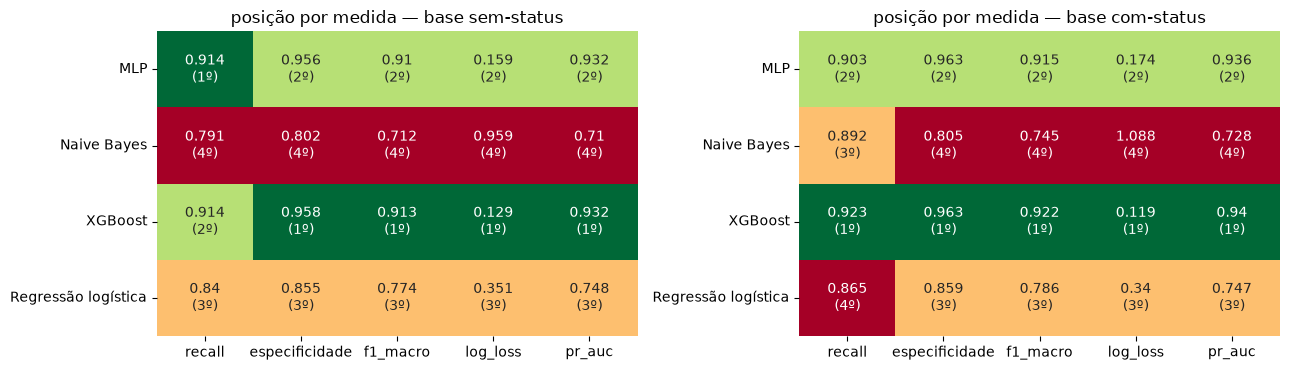

In [4]:
medias = pd.DataFrame([{'base': base, 'algoritmo': NOMES[alg], **res[(alg, base)]['por_fold'][METRICAS].mean()}
                       for base in BASES for alg in ALGORITMOS])

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, base in zip(eixos, BASES):
    sub = medias[medias['base'] == base].set_index('algoritmo')[METRICAS]
    ranks = sub.rank(ascending=False, method='min')
    ranks['log_loss'] = sub['log_loss'].rank(ascending=True, method='min')
    sns.heatmap(ranks.astype(int), annot=sub.round(3).astype(str) + '\n(' + ranks.astype(int).astype(str) + 'º)',
                fmt='', cmap='RdYlGn_r', vmin=1, vmax=4, cbar=False, ax=ax)
    ax.set_title(f'posição por medida — base {base}')
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'comparacao-ranking.png', dpi=150, bbox_inches='tight')
plt.show()

## Comparação pareada entre os algoritmos

Em cada base, o algoritmo de maior PR-AUC média é a referência. Para cada um dos outros, a diferença (outro − melhor) é calculada fold a fold, o que é possível porque todos usaram os mesmos folds. Se a diferença média for menor que o seu desvio, os dois não se distinguem além da variação entre folds. A última coluna conta em quantos dos 10 folds o melhor teve PR-AUC maior.

In [5]:
linhas_par = []
for base in BASES:
    sub = medias[medias['base'] == base]
    melhor_alg = [a for a in ALGORITMOS if NOMES[a] == sub.sort_values('pr_auc', ascending=False).iloc[0]['algoritmo']][0]
    ref = res[(melhor_alg, base)]
    for alg in ALGORITMOS:
        if alg == melhor_alg:
            continue
        outro = res[(alg, base)]
        vitorias = int((ref['por_fold']['pr_auc'] > outro['por_fold']['pr_auc']).sum())
        linhas_par.append({'base': base, 'comparação': f'{NOMES[alg]} − {NOMES[melhor_alg]}',
                           **diferenca_pareada(outro, ref),
                           f'folds em que o melhor vence (PR-AUC)': vitorias})
tab = pd.DataFrame(linhas_par)
salvar_tabela(tab, 'comparacao-tab-pareada')
tab

,base,comparação,recall,especificidade,f1_macro,log_loss,pr_auc,folds em que o melhor vence (PR-AUC)
0,sem-status,MLP − XGBoost,+0.000 ± 0.024,-0.002 ± 0.017,-0.003 ± 0.020,+0.030 ± 0.039,-0.001 ± 0.022,4
1,sem-status,Naive Bayes − XGBoost,-0.123 ± 0.080,-0.156 ± 0.026,-0.200 ± 0.038,+0.830 ± 0.246,-0.222 ± 0.077,10
2,sem-status,Regressão logística − XGBoost,-0.074 ± 0.059,-0.103 ± 0.028,-0.139 ± 0.032,+0.222 ± 0.042,-0.185 ± 0.063,10
3,com-status,MLP − XGBoost,-0.020 ± 0.025,-0.000 ± 0.013,-0.007 ± 0.021,+0.055 ± 0.054,-0.004 ± 0.017,7
4,com-status,Naive Bayes − XGBoost,-0.031 ± 0.053,-0.158 ± 0.034,-0.177 ± 0.042,+0.969 ± 0.266,-0.212 ± 0.086,10
5,com-status,Regressão logística − XGBoost,-0.058 ± 0.049,-0.104 ± 0.032,-0.136 ± 0.038,+0.221 ± 0.048,-0.193 ± 0.059,10


## Matrizes de confusão

Configuração escolhida de cada algoritmo, somada nos 10 folds.

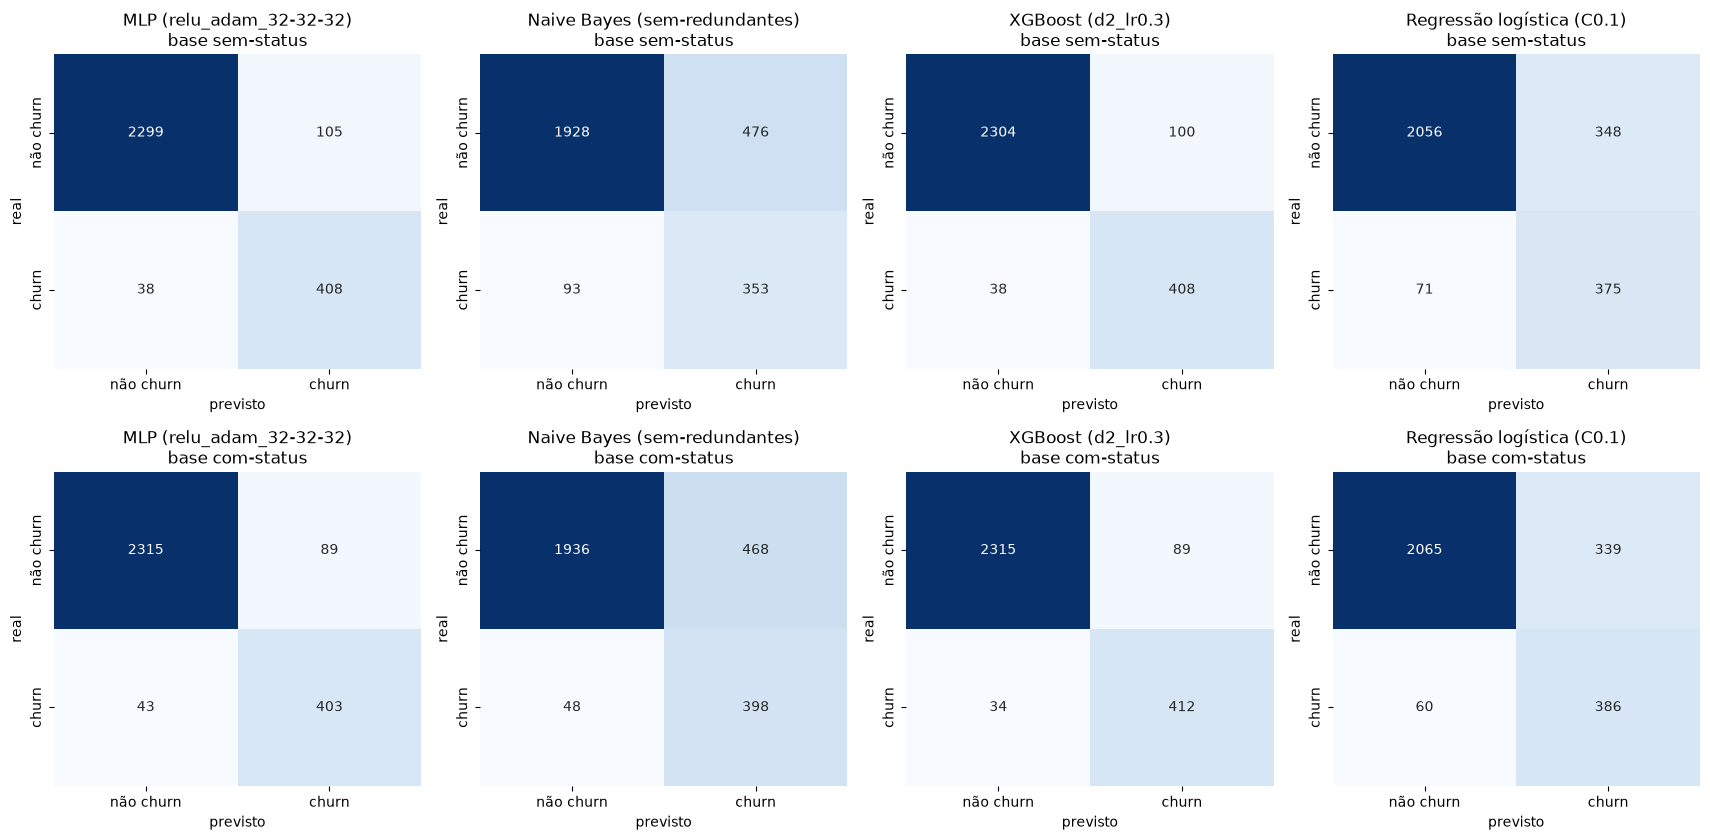

In [6]:
fig, eixos = plt.subplots(2, len(ALGORITMOS), figsize=(4.3 * len(ALGORITMOS), 8.5))
for i, base in enumerate(BASES):
    for j, alg in enumerate(ALGORITMOS):
        ax = eixos[i, j]
        sns.heatmap(res[(alg, base)]['matriz'], annot=True, fmt='d', cmap='Blues', cbar=False,
                    xticklabels=['não churn', 'churn'], yticklabels=['não churn', 'churn'], ax=ax)
        ax.set_title(f'{NOMES[alg]} ({ESCOLHIDAS[alg]})\nbase {base}')
        ax.set_xlabel('previsto')
        ax.set_ylabel('real')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'comparacao-matrizes.png', dpi=150, bbox_inches='tight')
plt.show()

## Curvas precisão-recall

Curva de cada algoritmo a partir das probabilidades fora do fold (cada cliente com a probabilidade prevista quando estava no teste). O ponto marca o limiar 0,5 usado nas demais medidas, e a linha tracejada é a linha de base (taxa de churn, 0,156).

A curva junta os 10 folds numa só, por isso a área sob ela pode diferir um pouco da média da PR-AUC por fold da tabela.

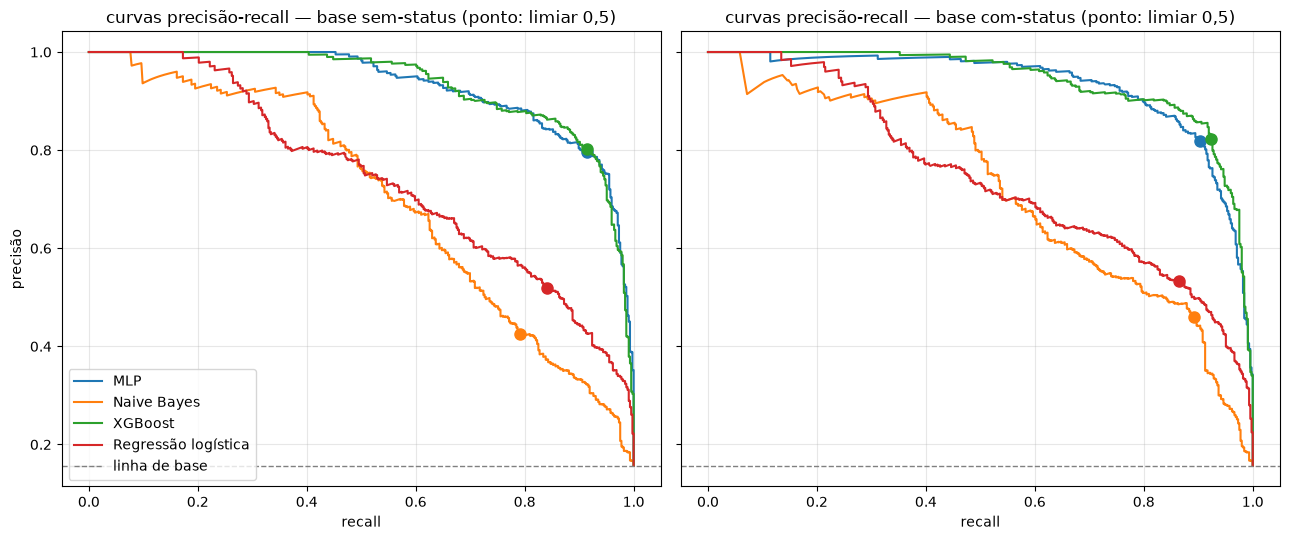

In [7]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
for ax, base in zip(eixos, BASES):
    for alg in ALGORITMOS:
        p = probas[(alg, ESCOLHIDAS[alg], base)]
        precisao, recall, _ = precision_recall_curve(y, p)
        linha, = ax.plot(recall, precisao, label=NOMES[alg])
        pred = p >= 0.5
        vp = (pred & (y == 1)).sum()
        ax.plot(vp / (y == 1).sum(), vp / max(pred.sum(), 1), 'o', color=linha.get_color(), ms=8)
    ax.axhline(TAXA_CHURN, color='gray', ls='--', lw=1, label='linha de base')
    ax.set_title(f'curvas precisão-recall — base {base} (ponto: limiar 0,5)')
    ax.set_xlabel('recall')
    ax.grid(alpha=0.3)
eixos[0].set_ylabel('precisão')
eixos[0].legend(loc='lower left')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'comparacao-curvas-pr.png', dpi=150, bbox_inches='tight')
plt.show()

## Comportamento dos erros

Os algoritmos erram nos **mesmos clientes**? Com as probabilidades fora do fold e o limiar 0,5, identificamos os churns perdidos (FN) e os falsos alarmes (FP) de cada algoritmo, na base sem `inativo`. A sobreposição entre dois algoritmos é medida pelo **índice de Jaccard**: |A ∩ B| / |A ∪ B|, de 0 (nenhum erro em comum) a 1 (os mesmos erros).

MLP                  FN   38 (matriz 38) | FP  105 (matriz 105)
Naive Bayes          FN   93 (matriz 93) | FP  476 (matriz 476)
XGBoost              FN   38 (matriz 38) | FP  100 (matriz 100)
Regressão logística  FN   71 (matriz 71) | FP  348 (matriz 348)


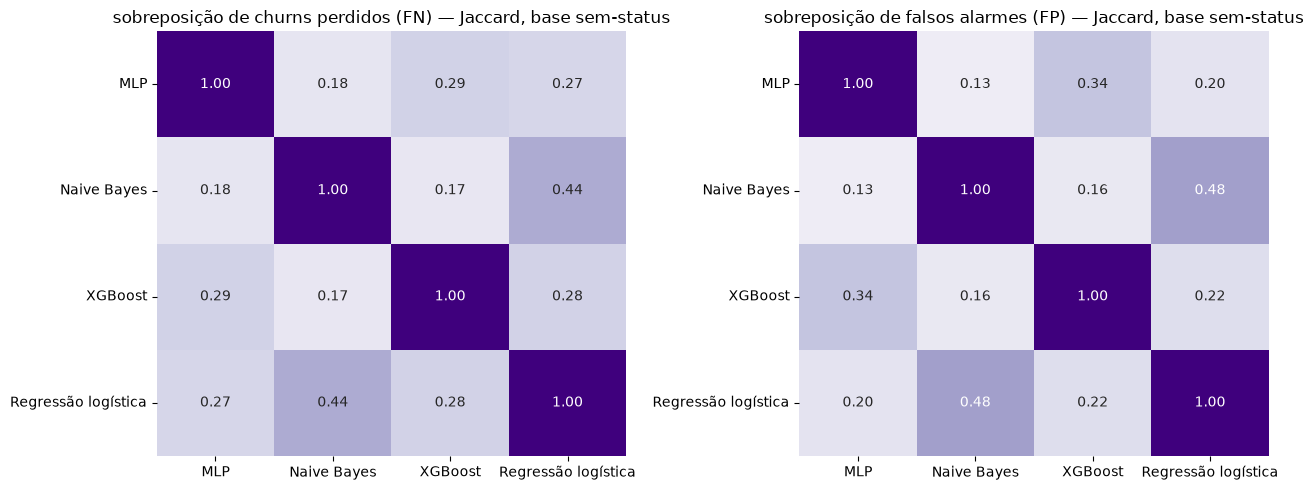

In [8]:
BASE_ERROS = 'sem-status'
pred = {alg: probas[(alg, ESCOLHIDAS[alg], BASE_ERROS)] >= 0.5 for alg in ALGORITMOS}
erros_fn = {alg: set(np.where(~pred[alg] & (y == 1))[0]) for alg in ALGORITMOS}
erros_fp = {alg: set(np.where(pred[alg] & (y == 0))[0]) for alg in ALGORITMOS}

# conferência com as matrizes salvas (pode diferir em clientes com probabilidade exatamente 0,5)
for alg in ALGORITMOS:
    (tn, fp), (fn, tp) = res[(alg, BASE_ERROS)]['matriz']
    print(f'{NOMES[alg]:<20} FN {len(erros_fn[alg]):>4} (matriz {fn}) | FP {len(erros_fp[alg]):>4} (matriz {fp})')


def jaccard(a, b):
    return len(a & b) / len(a | b) if a | b else np.nan


fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
for ax, (titulo, erros) in zip(eixos, [('churns perdidos (FN)', erros_fn), ('falsos alarmes (FP)', erros_fp)]):
    mat = pd.DataFrame([[jaccard(erros[a], erros[b]) for b in ALGORITMOS] for a in ALGORITMOS],
                       index=[NOMES[a] for a in ALGORITMOS], columns=[NOMES[a] for a in ALGORITMOS])
    sns.heatmap(mat, annot=True, fmt='.2f', cmap='Purples', vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(f'sobreposição de {titulo} — Jaccard, base {BASE_ERROS}')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'comparacao-erros-sobreposicao.png', dpi=150, bbox_inches='tight')
plt.show()

### Clientes que todos os algoritmos erram

Clientes classificados errado pelos quatro algoritmos ao mesmo tempo, comparados ao restante da classe real. Se esses clientes têm perfil típico da classe oposta (por exemplo, churns que nunca reclamaram e usam muito o serviço), o erro tende a vir dos dados, e não do algoritmo: ruído de rótulo (a base tem 14 combinações de atributos com churn 0 e 1) ou falta de informação nos atributos.

In [9]:
X_com, _ = carregar_base(com_status=True)
perfil = pd.DataFrame({
    'reclamou': X_com['reclamacao'],
    'inativo': X_com['inativo'],
    'plano contratual': X_com['plano_contratual'],
    'sem uso': (X_com['qtd_ligacoes'] == 0).astype(int),
    'ligações (mediana)': np.expm1(X_com['qtd_ligacoes']),
    'meses de assinatura (mediana)': X_com['meses_assinatura'],
})

todos_fn = set.intersection(*erros_fn.values())
todos_fp = set.intersection(*erros_fp.values())
print(f'churns perdidos por todos: {len(todos_fn)} de {N_CHURN}')
print(f'falsos alarmes de todos:   {len(todos_fp)} de {N_LINHAS - N_CHURN}')


def resumo_perfil(idx):
    sub = perfil.iloc[sorted(idx)]
    out = sub[['reclamou', 'inativo', 'plano contratual', 'sem uso']].mean().round(3)
    out['ligações (mediana)'] = sub['ligações (mediana)'].median()
    out['meses de assinatura (mediana)'] = sub['meses de assinatura (mediana)'].median()
    out['clientes'] = len(sub)
    return out


churn_idx = set(np.where(y == 1)[0])
fica_idx = set(np.where(y == 0)[0])
perfil_erros = pd.DataFrame({
    'churns perdidos por todos': resumo_perfil(todos_fn),
    'demais churns': resumo_perfil(churn_idx - todos_fn),
    'falsos alarmes de todos': resumo_perfil(todos_fp),
    'demais não churns': resumo_perfil(fica_idx - todos_fp),
})
salvar_tabela(perfil_erros, 'comparacao-tab-erros-comuns')
perfil_erros

churns perdidos por todos: 9 de 446
falsos alarmes de todos:   43 de 2404


,churns perdidos por todos,demais churns,falsos alarmes de todos,demais não churns
reclamou,0.111,0.432,0.093,0.015
inativo,0.222,0.739,0.721,0.139
plano contratual,0.111,0.011,0.000,0.094
sem uso,0.000,0.128,0.512,0.012
ligações (mediana),82.000,27.000,0.000,65.000
meses de assinatura (mediana),34.000,35.000,35.000,35.000
clientes,9.000,437.000,43.000,2361.000


## Efeito do desbalanceamento (consolidado)

Para cada algoritmo, uma configuração com e sem o tratamento do desbalanceamento, comparadas fold a fold:
- MLP: `relu_adam_32` com e sem `sample_weight`;
- Naive Bayes: `completo` (priors 0,5 / 0,5) × `priors-base` (priors do treino);
- XGBoost e regressão logística: a configuração escolhida com e sem `scale_pos_weight` / `class_weight`.

,algoritmo,base,versão,recall,especificidade,f1_macro,log_loss,pr_auc,FN (churns perdidos),FP (falsos alarmes)
0,MLP,sem-status,com tratamento,0.944 ± 0.048,0.907 ± 0.012,0.859 ± 0.017,0.202 ± 0.021,0.893 ± 0.048,25.0,224.0
1,MLP,sem-status,sem tratamento,0.679 ± 0.087,0.979 ± 0.008,0.858 ± 0.044,0.160 ± 0.033,0.874 ± 0.055,143.0,51.0
2,MLP,sem-status,diferença (sem − com),-0.264 ± 0.081,+0.072 ± 0.017,-0.001 ± 0.045,-0.042 ± 0.018,-0.019 ± 0.011,NaN,NaN
3,Naive Bayes,sem-status,com tratamento,0.774 ± 0.057,0.836 ± 0.013,0.736 ± 0.022,1.120 ± 0.342,0.696 ± 0.110,101.0,394.0
4,Naive Bayes,sem-status,sem tratamento,0.699 ± 0.080,0.900 ± 0.015,0.772 ± 0.038,0.967 ± 0.343,0.696 ± 0.110,134.0,241.0
5,Naive Bayes,sem-status,diferença (sem − com),-0.074 ± 0.046,+0.064 ± 0.016,+0.036 ± 0.025,-0.153 ± 0.017,+0.000 ± 0.000,NaN,NaN
6,XGBoost,sem-status,com tratamento,0.914 ± 0.059,0.958 ± 0.012,0.913 ± 0.026,0.129 ± 0.037,0.932 ± 0.037,38.0,100.0
7,XGBoost,sem-status,sem tratamento,0.796 ± 0.092,0.979 ± 0.010,0.901 ± 0.040,0.115 ± 0.034,0.932 ± 0.038,91.0,51.0
8,XGBoost,sem-status,diferença (sem − com),-0.119 ± 0.063,+0.020 ± 0.007,-0.012 ± 0.030,-0.015 ± 0.018,-0.001 ± 0.010,NaN,NaN
9,Regressão logística,sem-status,com tratamento,0.840 ± 0.082,0.855 ± 0.023,0.774 ± 0.033,0.351 ± 0.032,0.748 ± 0.082,71.0,348.0


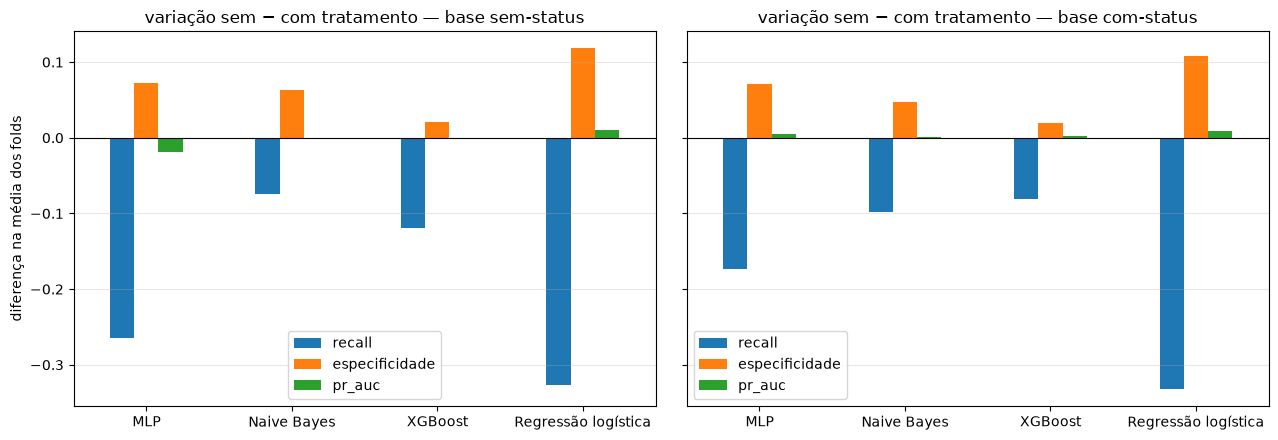

In [10]:
PARES_DESB = {
    'mlp': ('relu_adam_32', 'relu_adam_32_sem-pesos'),
    'nb': ('completo', 'priors-base'),
    'xgb': (ESCOLHIDAS['xgb'], f'{ESCOLHIDAS["xgb"]}_sem-pesos'),
    'rl': (ESCOLHIDAS['rl'], f'{ESCOLHIDAS["rl"]}_sem-pesos'),
}

linhas_desb, variacao = [], []
for base in BASES:
    for alg, (com_trat, sem_trat) in PARES_DESB.items():
        r_com = resultado_salvo(metricas, matrizes, alg, com_trat, base)
        r_sem = resultado_salvo(metricas, matrizes, alg, sem_trat, base)
        for linha in tabela_desbalanceamento(r_com, r_sem, base):
            linhas_desb.append({'algoritmo': NOMES[alg], **linha})
        dif = r_sem['por_fold'][METRICAS].mean() - r_com['por_fold'][METRICAS].mean()
        variacao.append({'base': base, 'algoritmo': NOMES[alg], **dif})
tab = pd.DataFrame(linhas_desb)
display(tab)
salvar_tabela(tab, 'comparacao-tab-desbalanceamento')

variacao = pd.DataFrame(variacao)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, base in zip(eixos, BASES):
    sub = variacao[variacao['base'] == base].set_index('algoritmo')[['recall', 'especificidade', 'pr_auc']]
    sub.plot.bar(ax=ax, rot=0)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'variação sem − com tratamento — base {base}')
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=0.3)
eixos[0].set_ylabel('diferença na média dos folds')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'comparacao-desbalanceamento.png', dpi=150, bbox_inches='tight')
plt.show()

## Efeito do `inativo` (consolidado)

Diferença fold a fold (base com `inativo` − base sem `inativo`) na configuração escolhida de cada algoritmo. Valores positivos indicam que o atributo melhora a métrica, o que, sob a suspeita de vazamento, mede quanto ele "infla" os resultados.

In [11]:
tab = pd.DataFrame([{'algoritmo': NOMES[alg], 'config': ESCOLHIDAS[alg],
               **diferenca_pareada(res[(alg, 'com-status')], res[(alg, 'sem-status')])}
              for alg in ALGORITMOS])
salvar_tabela(tab, 'comparacao-tab-efeito-inativo')
tab

,algoritmo,config,recall,especificidade,f1_macro,log_loss,pr_auc
0,MLP,relu_adam_32-32-32,-0.011 ± 0.034,+0.007 ± 0.011,+0.005 ± 0.016,+0.015 ± 0.049,+0.004 ± 0.022
1,Naive Bayes,sem-redundantes,+0.101 ± 0.044,+0.003 ± 0.021,+0.032 ± 0.019,+0.129 ± 0.033,+0.018 ± 0.015
2,XGBoost,d2_lr0.3,+0.009 ± 0.026,+0.005 ± 0.007,+0.009 ± 0.009,-0.010 ± 0.014,+0.008 ± 0.015
3,Regressão logística,C0.1,+0.025 ± 0.034,+0.004 ± 0.011,+0.011 ± 0.014,-0.011 ± 0.011,-0.000 ± 0.020


## Discussão

Valores na base sem `inativo` (a referência), em média ± desvio nos 10 folds, salvo indicação. Configurações escolhidas: MLP `relu_adam_32-32-32`, XGBoost `d2_lr0.3`, regressão logística `C0.1` e Naive Bayes `sem-redundantes`.

### Qual algoritmo apresentou o melhor desempenho? A resposta depende da medida?

XGBoost e MLP empatam no topo, e regressão logística e Naive Bayes ficam bem atrás.
- Os dois primeiros têm o mesmo recall (0,914) e a mesma PR-AUC (0,932). Na comparação pareada, a diferença MLP − XGBoost é de −0,001 ± 0,022 na PR-AUC (o XGBoost vence em só 4 dos 10 folds), −0,003 ± 0,020 no F1 macro e +0,030 ± 0,039 no log loss, todas dentro da variação entre folds. Na base com `inativo` o quadro se repete (PR-AUC 0,940 contra 0,936; diferença −0,004 ± 0,017).
- A regressão logística (PR-AUC 0,748) e o Naive Bayes (0,710) perdem para o XGBoost em todos os 10 folds, por −0,185 ± 0,063 e −0,222 ± 0,077.

Com as medidas que resumem o modelo inteiro (PR-AUC, F1 macro e log loss), a ordem é a mesma nas duas bases: XGBoost ≈ MLP > regressão logística > Naive Bayes. A resposta muda quando se olha uma medida isolada no limiar 0,5:
- XGBoost e MLP trocam de posição conforme a medida, sempre por diferenças menores que o desvio (na base com `inativo`, o XGBoost tem mais recall, 0,923 contra 0,903, e a especificidade empata em 0,963).
- No recall, a ordem entre os dois mais fracos depende da base: sem `inativo`, a regressão logística passa o NB (0,840 contra 0,791); com `inativo`, o NB passa a regressão logística (0,892 contra 0,865).
- O maior recall entre todas as configurações salvas é da MLP de 1 camada (0,944), com especificidade de 0,907; o NB sem `log1p` chega a 0,932 de recall com especificidade de 0,602. Na outra ponta, a regra "reclamou → churn" tem especificidade de 0,983 e o classificador trivial, 1,000.

Recall e especificidade sozinhos medem o ponto de operação, que os pesos de classe e o limiar deslocam. Por isso a escolha foi feita pela PR-AUC, que não depende do limiar.

### A alteração dos parâmetros modificou os resultados?

Sim, quando a mudança levava o modelo ao subajuste. Fora dessa faixa, os resultados formam um patamar.

Mudanças grandes:
- otimizador da MLP: com SGD puro, a PR-AUC cai para 0,562 (1 camada) e 0,486 (2 camadas), contra 0,893 e 0,929 com Adam, porque o SGD não termina de treinar em 200 épocas;
- profundidade da MLP: de 1 para 2 camadas, a PR-AUC sobe de 0,893 para 0,929 e os falsos alarmes caem de 224 para 105 (com 3 camadas);
- regularização da regressão logística: com `C` = 0,01 e 0,001, a PR-AUC cai para 0,614 e 0,501;
- taxa × profundidade no XGBoost: de 0,856 (`d2_lr0.05`) a 0,940 (`d4_lr0.1`);
- `log1p` no NB: sem ele, a especificidade cai de 0,836 para 0,602 e o F1 macro perde 0,135.

Mudanças dentro da variação entre folds:
- ReLU × tanh (no máximo 0,019 de PR-AUC);
- `C` de 0,1 a 100 (PR-AUC de 0,748 a 0,765);
- XGBoost a partir de `d3_lr0.1` (9 das 12 configurações entre 0,927 e 0,940);
- NB sem `segundos_uso` (+0,014 ± 0,033).

Os pesos de classe e os priors mudam pouco a separação e muito o ponto de operação (ver o desbalanceamento, abaixo).

### Os algoritmos apresentaram comportamentos diferentes em relação aos erros de classificação?

Sim, na quantidade e em quais clientes cada um erra.

| algoritmo | churns perdidos (FN) | falsos alarmes (FP) | precisão no limiar 0,5 |
|---|---|---|---|
| XGBoost | 38 | 100 | 0,803 |
| MLP | 38 | 105 | 0,795 |
| Regressão logística | 71 | 348 | 0,519 |
| Naive Bayes | 93 | 476 | 0,426 |

Com o tratamento do desbalanceamento, todos erram mais em falsos alarmes do que em churns perdidos. A sobreposição dos erros (Jaccard) mostra dois grupos. NB e regressão logística erram nos mesmos clientes com mais frequência (0,44 nos FN e 0,48 nos FP). MLP e XGBoost, mesmo com métricas quase iguais, dividem só cerca de um terço dos erros (0,29 nos FN e 0,34 nos FP). Os demais pares ficam entre 0,13 e 0,28. Como os dois melhores erram em clientes diferentes, combiná-los poderia reduzir os erros, mas isso não foi testado.

Os erros comuns aos quatro são poucos e têm perfil claro:
- 43 dos 2404 clientes que ficam são falsos alarmes de todos. Desses, 51,2% não têm nenhum uso (contra 1,2% dos demais não churns) e 72,1% são inativos (contra 13,9%), com mediana de 0 ligações. Eles se parecem com quem sai: entre os clientes sem uso, 52,3% cancelam, e os atributos não distinguem a metade que fica.
- 9 dos 446 churns são perdidos por todos. Eles têm mediana de 82 ligações (contra 27 dos demais churns), só 11,1% reclamaram (contra 43,2%) e 22,2% estão inativos (contra 73,9%), um perfil de quem fica.

Esses erros vêm dos dados (ruído de rótulo ou falta de informação nos atributos), e nenhum dos algoritmos os resolve.

### O desbalanceamento das classes, caso exista, influenciou a avaliação?

Sim. A base tem 15,6% de churn (446 de 2850), e o desbalanceamento pesou em dois pontos.

Na escolha das medidas, o classificador que responde sempre "não churn" teria 84,4% de acurácia com recall zero. Por isso a acurácia e a ROC-AUC foram descartadas, e a PR-AUC foi lida contra a sua linha de base, 0,156.

No treino, cada algoritmo foi comparado com e sem o tratamento (diferença sem − com, base sem `inativo`):

| algoritmo | recall | especificidade | PR-AUC | log loss | FN (com → sem) |
|---|---|---|---|---|---|
| Regressão logística | −0,327 | +0,118 | +0,010 | −0,114 | 71 → 217 |
| MLP (`relu_adam_32`) | −0,264 | +0,072 | −0,019 | −0,042 | 25 → 143 |
| XGBoost | −0,119 | +0,020 | −0,001 | −0,015 | 38 → 91 |
| Naive Bayes (`completo`) | −0,074 | +0,064 | 0,000 | −0,153 | 101 → 134 |

Sem tratamento, os modelos apontam menos clientes como churn: o recall cai e a especificidade sobe, enquanto a PR-AUC muda no máximo 0,019. O desbalanceamento desloca o ponto de operação e quase não altera a capacidade de separar as classes. O log loss melhora sem os pesos porque as probabilidades voltam a refletir a proporção real de churn; com os pesos, elas superestimam o churn, o que não atrapalha a ordenação dos clientes. O F1 macro quase não percebe a troca (de −0,012 a +0,036), embora ela custe de 33 a 146 churns perdidos a mais. Por isso o recall é a métrica principal.

### Quais características da base de dados podem explicar as diferenças observadas?

- **Reclamação forte, mas incompleta**: 82,6% de quem reclamou sai, e a reclamação é o atributo mais importante em todos os modelos (odds ratio de 15,2 na regressão logística, 41,5% do ganho no XGBoost). Como 57% dos churns nunca reclamaram, os modelos precisam combinar a reclamação com o uso, e todos encontram muito mais churns que a regra "reclamou → churn" (recall 0,426).
- **Não linearidades e interações**: idade com churn quase nulo nos extremos, faixa de cobrança, falhas que pesam em relação ao volume de ligações e o limiar de uso zero. O modelo linear perde 0,185 de PR-AUC para o XGBoost. Árvores de profundidade 2, que combinam pares de atributos, já bastam, e a MLP melhora ao passar de 1 para 2 camadas.
- **Atributos que violam as suposições do NB**: os atributos de uso são correlacionados entre si, há binários e uma idade com 5 valores tratados como gaussianos, e há muitos zeros. O NB conta a mesma evidência várias vezes, e o seu log loss (0,959) fica acima do de um modelo que prevê 15,6% para todos (0,433). O `log1p` é a transformação que mais ajuda o NB (sem ele, a especificidade cai 0,234).
- **Clientes sem uso**: os 107 clientes sem nenhum uso se dividem quase ao meio entre churn e não churn (52,3% saem) e são metade dos 43 falsos alarmes comuns aos quatro algoritmos.
- **`inativo`**: efeito pequeno, exceto no NB. Na comparação pareada com − sem, a PR-AUC muda +0,004 na MLP, +0,008 no XGBoost, −0,000 na regressão logística e +0,018 no NB (que também ganha 0,101 de recall). No XGBoost, `inativo` fica com 47,6% do ganho e tira importância da reclamação e do uso, sinal de que repete informação já presente nas outras colunas. A suspeita de vazamento não se traduziu em resultados inflados.
- **Base pequena e ruidosa**: são 446 churns e 14 combinações de atributos com rótulos conflitantes. O desvio da PR-AUC entre folds vai de 0,035 a 0,1, então várias diferenças (MLP × XGBoost, valores de `C`, ativações) ficam dentro da variação. Os números das configurações escolhidas são levemente otimistas, porque a escolha e a avaliação usaram os mesmos folds.

### Qual modelo você recomendaria para o problema investigado?

O XGBoost `d2_lr0.3` (300 árvores de profundidade 2, taxa 0,3, `scale_pos_weight`), treinado sem `inativo`.

- **Desempenho**: empata com a MLP em PR-AUC e recall (0,932 e 0,914), com menos falsos alarmes (100) e o menor log loss (0,129). No limiar 0,5, encontra 408 dos 446 churns, e 80% dos alertas estão corretos.
- **Estabilidade e custo**: são árvores rasas, sem padronização, treinadas em segundos. A MLP equivalente precisa de 3 camadas, não converge em 200 épocas, despenca com outro otimizador (PR-AUC 0,56 com SGD) e perde mais recall sem pesos de classe (−0,264, contra −0,119 do XGBoost). O XGBoost também é estável na grade: 9 das 12 configurações dão PR-AUC entre 0,927 e 0,940.
- **Interpretação**: a importância por `gain` confirma as hipóteses (reclamação, valor do cliente e uso), o que ajuda a explicar à administração quem será abordado e por quê. Os coeficientes da regressão logística podem complementar a explicação (reclamar multiplica a chance de churn por 15), mas como classificador ela daria 3,5 vezes mais falsos alarmes (348 contra 100) e perderia 33 churns a mais.
- **Sem `inativo`**: o status pode não estar disponível com 3 meses de antecedência e pode antecipar o próprio rótulo. Deixá-lo de fora custa só 0,008 de PR-AUC.
- **Ponto de operação**: o limiar 0,5 com pesos de classe dá recall de 0,91. Pela curva precisão-recall, a precisão fica perto de 0,8 até um recall de cerca de 0,9 e cai rápido depois disso. Se a ação de retenção for barata, o limiar pode descer um pouco; se for cara, subir.

Ressalva: a diferença entre XGBoost e MLP está dentro da variação entre folds. Em desempenho os dois são equivalentes, e a recomendação se apoia no custo, na estabilidade e na interpretação.